# Weather Prediction with ERA5

**AI SCI 290A, Weather Project**

Can we predict tomorrow's weather from today's? We use daily means of temperature, pressure, precipitation and wind speed over the continental US for 2009 and 2010 (ERA5). We will:

1. Load the data and look at it on a map and over time
2. Choose one location and build a table of features
3. Add 3-day and 7-day rolling averages
4. Predict tomorrow's temperature: baseline, linear regression, more features, a neural network
5. Predict the change in temperature, and use neighboring locations
6. Predict 2 and 3 days ahead
7. Repeat for precipitation
8. Predict extreme heat days

**Before you start:** unpack `data.tgz` and set `DATA_DIR` below to the folder that holds the `.nc` files.

## 0. Setup

In [59]:
import glob
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score

warnings.filterwarnings("ignore")    # hide the neural network convergence warnings

DATA_DIR = Path("/Users/matchew/AISCI290A/Data/data.tgz")
print("Data folder", "found" if DATA_DIR.exists() else "NOT FOUND: check DATA_DIR")

Data folder found


## 1. Load the data

Each feature lives in its own set of `.nc` files. `open_mfdataset` merges the files of one feature into a single dataset, and each dataset holds one variable, so `list(ds.data_vars)[0]` picks it.

If a count below is 0, the text in `load("...")` doesn't match your file names. Look at the names with `sorted(DATA_DIR.rglob("*.nc"))` and change it.

We also convert to units we can read: temperature to °C, precipitation to mm, pressure to hPa.

In [60]:
print("DATA_DIR:", DATA_DIR, "| exists:", DATA_DIR.exists())
print("Running in:", Path.cwd())

nc_files = sorted(DATA_DIR.rglob("*.nc"))
print(len(nc_files), "files found")
for f in nc_files[:10]:
    print(f.name)

DATA_DIR: /Users/matchew/AISCI290A/Data/data.tgz | exists: True
Running in: /Users/matchew/AISCI290A
0 files found


In [61]:
import tarfile

TGZ_FILE = Path("/Users/matchew/AISCI290A/Data/data.tgz")
DATA_DIR = Path("/Users/matchew/AISCI290A/Data/era5")

if not DATA_DIR.exists():
    DATA_DIR.mkdir()
    with tarfile.open(TGZ_FILE) as tar:
        tar.extractall(DATA_DIR)

print(len(sorted(DATA_DIR.rglob("*.nc"))), "files found")

120 files found


In [62]:
names = sorted(set(f.name for f in DATA_DIR.rglob("*.nc")))
print(len(names), "files")
for n in names[:10]:
    print(n)

10 files
._10m_u_component_of_wind_stream-oper_daily-mean.nc
._10m_v_component_of_wind_0_daily-mean.nc
._2m_temperature_0_daily-mean.nc
._mean_sea_level_pressure_0_daily-mean.nc
._total_precipitation_0_daily-mean.nc
10m_u_component_of_wind_stream-oper_daily-mean.nc
10m_v_component_of_wind_0_daily-mean.nc
2m_temperature_0_daily-mean.nc
mean_sea_level_pressure_0_daily-mean.nc
total_precipitation_0_daily-mean.nc


In [63]:
T2M_C = load("2m_temperature") - 273.15
PRECIP = load("total_precipitation") * 1000
PRESSURE = load("mean_sea_level_pressure") / 100

U = load("10m_u_component_of_wind")
V = load("10m_v_component_of_wind")
WIND = np.sqrt(U**2 + V**2)

2m_temperature            12 files
total_precipitation       12 files
mean_sea_level_pressure   12 files
10m_u_component_of_wind   12 files
10m_v_component_of_wind   12 files


In [64]:
def load(name):
    files = sorted(glob.glob(f"{DATA_DIR}/**/*{name}*.nc", recursive = True))
    print(f"{name:25s} {len(files)} files")
    ds = xr.open_mfdataset(files, combine = "by_coords")
    return ds[list(ds.data_vars)[0]]

T2M_C = load("2m_temperature") - 273.15
PRECIP = load("total_precipitation") * 1000
PRESSURE = load("mean_sea_level_pressure") / 100

U = load("10m_u_component_of_wind")
V = load("10m_v_component_of_wind")
WIND = np.sqrt(U**2 + V**2)

2m_temperature            12 files
total_precipitation       12 files
mean_sea_level_pressure   12 files
10m_u_component_of_wind   12 files
10m_v_component_of_wind   12 files


In [65]:
# Dimensions: time x latitude x longitude
T2M_C

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<sub, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31

## 2. Look at the data

### Temperature on one day

`isel(valid_time=0)` picks the first day by position, which leaves a latitude x longitude grid. That is a heat map.

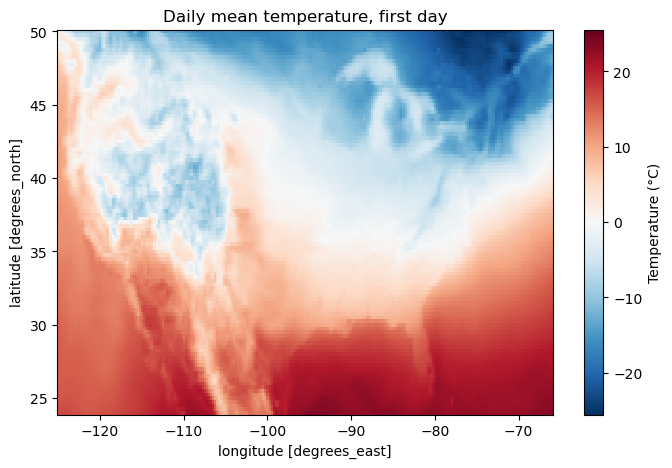

In [66]:
day0 = T2M_C.isel(valid_time=0)

fig, ax = plt.subplots(figsize=(8, 5))
day0.plot(ax=ax, cmap="RdBu_r", cbar_kwargs={"label": "Temperature (°C)"})
ax.set_title("Daily mean temperature, first day")
plt.show()

### Temperature at one location over time

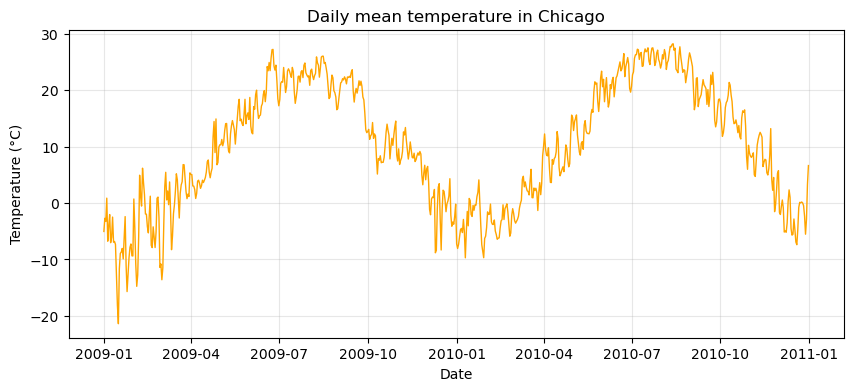

In [67]:
LAT = 41.9
LON = -87.6

T_chi = T2M_C.sel(latitude=LAT, longitude=LON, method="nearest")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(T_chi["valid_time"], T_chi, lw=1, color="orange")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily mean temperature in Chicago")
ax.grid(alpha=0.3)
plt.show()

### The same for precipitation

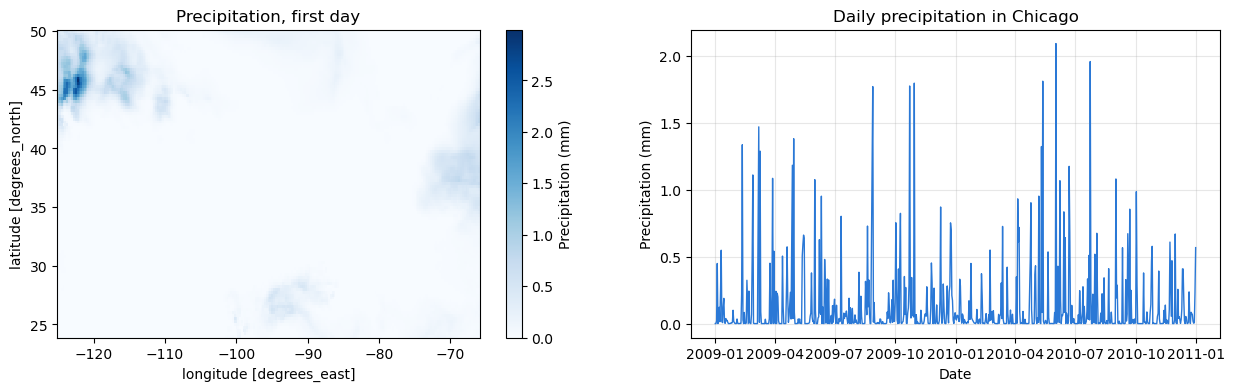

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

PRECIP.isel(valid_time=0).plot(ax=axes[0], cmap="Blues", cbar_kwargs={"label": "Precipitation (mm)"})
axes[0].set_title("Precipitation, first day")

P_chi = PRECIP.sel(latitude=LAT, longitude=LON, method="nearest")
axes[1].plot(P_chi["valid_time"], P_chi, lw=1, color="#2a78d6")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Precipitation (mm)")
axes[1].set_title("Daily precipitation in Chicago")
axes[1].grid(alpha=0.3)
plt.show()

**Question:** temperature has a smooth seasonal cycle, but precipitation is spiky: mostly near zero with sudden bursts. Which one do you expect to be easier to predict?

## 3. One location, one table

We study Chicago. We pull each feature out at that location and put them side by side in a DataFrame, with the date as the index. From here on this is ordinary pandas.

In [69]:
def at(da, dlat=0, dlon=0):
    return da.sel(latitude=LAT + dlat, longitude=LON + dlon, method="nearest").values

dates = T2M_C["valid_time"].values

df = pd.DataFrame({"temp": at(T2M_C), "precip": at(PRECIP),
                   "pressure": at(PRESSURE), "wind": at(WIND)}, index=dates)
df.describe().round(2)

,temp,precip,pressure,wind
count,730.00,730.00,730.00,730.00
mean,10.09,0.13,1016.38,4.82
std,10.90,0.28,7.21,2.33
min,-21.40,0.00,988.49,0.42
25%,0.96,0.00,1011.82,3.07
50%,10.26,0.01,1016.28,4.50
75%,20.32,0.10,1020.75,6.40
max,28.25,2.09,1040.87,14.32


In [70]:
df.isna().sum()

temp        0
precip      0
pressure    0
wind        0
dtype: int64

## 4. Rolling averages

A **rolling average** replaces each day with the mean of the last few days, so it smooths out day-to-day noise. `rolling(3).mean()` uses today and the 2 days before it, never the future. The first few days have no full window, so they become `NaN`.

In [71]:
BASE = ["temp", "precip", "pressure", "wind"]

for col in BASE:
    df[col + "_3d"] = df[col].rolling(3).mean()
    df[col + "_7d"] = df[col].rolling(7).mean()

ROLL = [c + "_3d" for c in BASE] + [c + "_7d" for c in BASE]
df[["temp", "temp_3d", "temp_7d"]].head(10).round(2)

,temp,temp_3d,temp_7d
2009-01-01,-5.04,NaN,NaN
2009-01-02,-2.70,NaN,NaN
2009-01-03,-3.25,-3.66,NaN
2009-01-04,0.87,-1.69,NaN
2009-01-05,-6.77,-3.05,NaN
2009-01-06,-4.10,-3.33,NaN
2009-01-07,-2.04,-4.30,-3.29
2009-01-08,-7.03,-4.39,-3.57
2009-01-09,-6.10,-5.06,-4.06
2009-01-10,-2.49,-5.21,-3.95


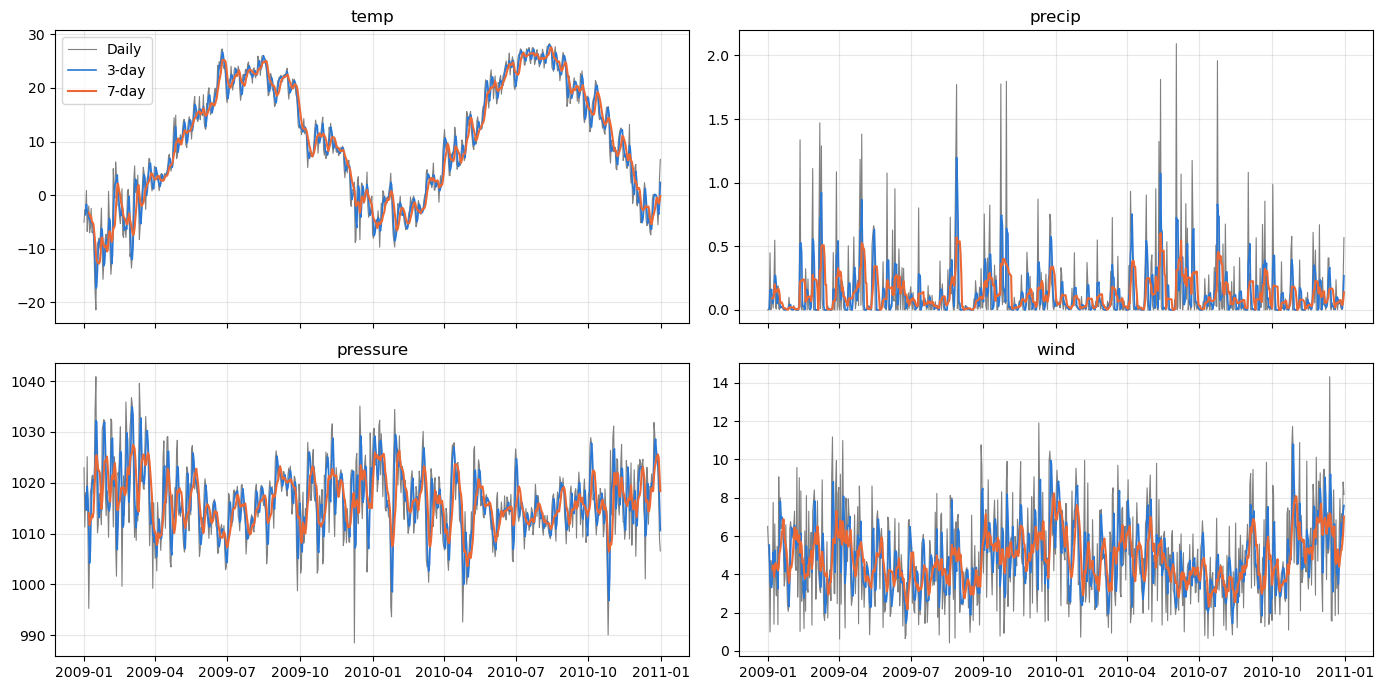

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, col in zip(axes.flat, BASE):
    ax.plot(df.index, df[col], lw=0.8, color="gray", label="Daily")
    ax.plot(df.index, df[col + "_3d"], lw=1.2, color="#2a78d6", label="3-day")
    ax.plot(df.index, df[col + "_7d"], lw=1.5, color="#eb6834", label="7-day")
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Question:** the 7-day line lags behind the daily line (look at a sudden warm-up). Why does averaging past days always cause a lag?

## 5. Train and test sets for time series

On the MAGIC data we split at random. Here that would be a mistake: neighboring days are almost the same, so a random test day always has a near copy in the training set. Instead we **train on 2009 and test on 2010**. Each year holds every season, so the test set is a fair mix.

The function below does one experiment: choose the input columns, the quantity to predict and how many days ahead, and it returns the **mean absolute error** (MAE) on 2010, in the units of that quantity. Lower is better.

- `delta=True` predicts the *change* from today instead of the value, then adds today back, so the error is still in the same units
- `model="persistence"` means "tomorrow will be the same as today"
- `model="mean"` means "always predict the 2009 average"

In [73]:
def run(cols, var="temp", days=1, delta=False, model=None):
    d = df[cols].copy()
    d["now"] = df[var]
    d["y_abs"] = df[var].shift(-days)
    d["y"] = d["y_abs"] - d["now"] if delta else d["y_abs"]
    d = d.dropna()

    train = d[d.index.year == 2009]
    test = d[d.index.year == 2010]

    if model == "persistence":
        pred = test["now"]
    elif model == "mean":
        pred = np.full(len(test), train["y_abs"].mean())
    else:
        model = LinearRegression() if model is None else model
        scaler = StandardScaler().fit(train[cols])
        model.fit(scaler.transform(train[cols]), train["y"])
        pred = model.predict(scaler.transform(test[cols]))
        if delta:
            pred = pred + test["now"]

    return mean_absolute_error(test["y_abs"], pred)

## 6. Predict tomorrow's temperature

### Baselines

In [74]:
print("Always the 2009 average:", round(run(["temp"], model="mean"), 2), "°C")
print("Same as today:          ", round(run(["temp"], model="persistence"), 2), "°C")

Always the 2009 average: 9.76 °C
Same as today:           1.64 °C


Any model has to beat **both** of these to be worth anything. "Same as today" is hard to beat because weather changes slowly.

### Linear regression

In [75]:
print("Today's temp only:         ", round(run(["temp"]), 2), "°C")
print("Today's temp + 3d, 7d avgs:", round(run(["temp", "temp_3d", "temp_7d"]), 2), "°C")

Today's temp only:          1.67 °C
Today's temp + 3d, 7d avgs: 1.63 °C


### Adding more features

In [76]:
TODAY = BASE
features = {
    "temp only": ["temp"],
    "temp + temp rolling": ["temp", "temp_3d", "temp_7d"],
    "all four today": TODAY,
    "all four + all rolling": TODAY + ROLL,
}

for name, cols in features.items():
    print(f"{name:25s} MAE {run(cols):.2f} °C")

temp only                 MAE 1.67 °C
temp + temp rolling       MAE 1.63 °C
all four today            MAE 1.62 °C
all four + all rolling    MAE 1.57 °C


### A neural network

The same function takes any scikit-learn model. We use a small `MLPRegressor`, as in Week 3.

In [77]:
def make_net():
    return MLPRegressor(hidden_layer_sizes=(32,), max_iter=1000, random_state = 0)

for name, cols in features.items():
    print(f"{name:25s} MAE {run(cols, model=make_net()):.2f} °C")

temp only                 MAE 1.70 °C
temp + temp rolling       MAE 1.71 °C
all four today            MAE 1.63 °C
all four + all rolling    MAE 2.02 °C


**Question:** does the network beat linear regression? With only 365 training days, how much room does a network have to learn anything extra?

## 7. Predict the change instead

Predicting tomorrow's temperature mostly means copying today's. If we predict the **change** (tomorrow minus today), the model only has to learn what is new. For linear regression the two give the same answer, since "today" is already an input. For a neural network they don't.

In [78]:
cols = TODAY + ROLL

print("Linear, value: ", round(run(cols), 2))
print("Linear, change:", round(run(cols, delta=True), 2))
print("Network, value: ", round(run(cols, model=make_net()), 2))
print("Network, change:", round(run(cols, delta=True, model=make_net()), 2))

Linear, value:  1.57
Linear, change: 1.57
Network, value:  2.02
Network, change: 1.93


## 8. Use neighboring locations

Weather moves: tomorrow's weather in Chicago is partly today's weather somewhere upwind. We add temperature and pressure at 4 points, 3° north, south, east and west of Chicago.

In [79]:
OFFSETS = {"N": (3, 0), "S": (-3, 0), "E": (0, 3), "W": (0, -3)}

for name, (dlat, dlon) in OFFSETS.items():
    df["temp_" + name] = at(T2M_C, dlat, dlon)
    df["pressure_" + name] = at(PRESSURE, dlat, dlon)

NEAR = [p + "_" + n for p in ["temp", "pressure"] for n in OFFSETS]
NEAR

['temp_N',
 'temp_S',
 'temp_E',
 'temp_W',
 'pressure_N',
 'pressure_S',
 'pressure_E',
 'pressure_W']

In [80]:
for name, cols in {"Chicago only": TODAY + ROLL, "Chicago + neighbors": TODAY + ROLL + NEAR}.items():
    lin = run(cols, delta=True)
    net = run(cols, delta=True, model=make_net())
    print(f"{name:20s} linear {lin:.2f} °C   network {net:.2f} °C")

Chicago only         linear 1.57 °C   network 1.93 °C
Chicago + neighbors  linear 1.52 °C   network 1.65 °C


**Question:** which neighbor do you expect to help most? In the US, weather mostly moves from west to east. (Try adding only the `W` columns and see.)

## 9. Predict further ahead

The same function, with `days=2` and `days=3`. We expect the error to grow with the horizon.

1 day(s) ahead:  same-as-today 1.64   linear 1.52   network 1.65
2 day(s) ahead:  same-as-today 2.50   linear 2.27   network 2.79
3 day(s) ahead:  same-as-today 2.95   linear 2.61   network 3.29
4 day(s) ahead:  same-as-today 3.14   linear 2.75   network 3.28
5 day(s) ahead:  same-as-today 3.24   linear 2.90   network 3.14


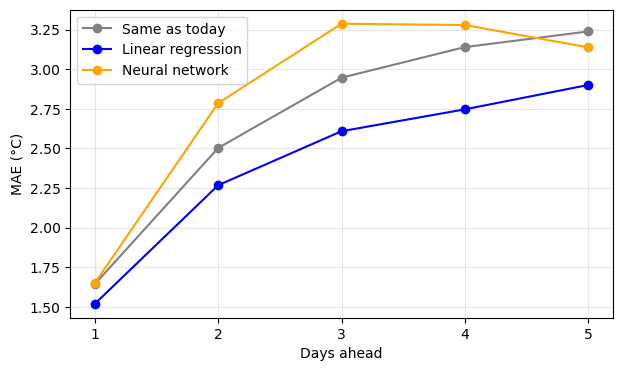

In [83]:
cols = TODAY + ROLL + NEAR
horizons = [1, 2, 3, 4, 5]
persistence, linear, network = [], [], []

for days in horizons:
    persistence.append(run(["temp"], days=days, model="persistence"))
    linear.append(run(cols, days=days, delta=True))
    network.append(run(cols, days=days, delta=True, model=make_net()))
    print(f"{days} day(s) ahead:  same-as-today {persistence[-1]:.2f}   linear {linear[-1]:.2f}   network {network[-1]:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(horizons, persistence, "o-", color="gray", label = "Same as today")
ax.plot(horizons, linear, "o-", color="blue", label = "Linear regression")
ax.plot(horizons, network, "o-", color="orange", label = "Neural network")
ax.set_xlabel("Days ahead")
ax.set_ylabel("MAE (°C)")
ax.set_xticks(horizons)
ax.legend()
ax.grid(alpha = 0.3)
plt.show()

            Same as today  Linear regression  Neural network  Random forest  Gradient boosting
days ahead                                                                                    
1                    1.64               1.52            1.65           1.53               1.58
2                    2.50               2.27            2.79           2.56               2.60
3                    2.95               2.61            3.29           3.07               3.19
4                    3.14               2.75            3.28           3.22               3.31
5                    3.24               2.90            3.14           3.29               3.46


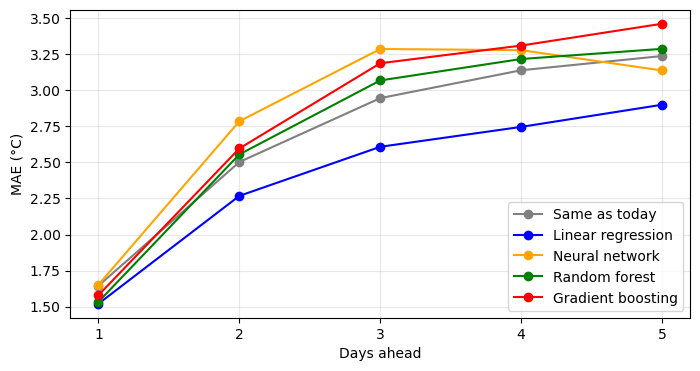

In [84]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

cols = TODAY + ROLL + NEAR
horizons = [1, 2, 3, 4, 5]

models = {
    "Same as today": "persistence",
    "Linear regression": None,
    "Neural network": "net",
    "Random forest": "rf",
    "Gradient boosting": "gb",
}
colors = ["gray", "blue", "orange", "green", "red"]


def make_model(kind):
    if kind == "net":
        return make_net()
    if kind == "rf":
        return RandomForestRegressor(n_estimators=100, max_depth=5, random_state=0)
    if kind == "gb":
        return GradientBoostingRegressor(n_estimators=100, max_depth=2, random_state=0)
    return kind         # "persistence" or None (linear regression)


errors = {}
for name, kind in models.items():
    use = ["temp"] if kind == "persistence" else cols
    errors[name] = [run(use, days=days, delta=True, model=make_model(kind)) for days in horizons]

results = pd.DataFrame(errors, index=horizons)
results.index.name = "days ahead"
print(results.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for name, color in zip(models, colors):
    ax.plot(horizons, results[name], "o-", color=color, label=name)
ax.set_xlabel("Days ahead")
ax.set_ylabel("MAE (°C)")
ax.set_xticks(horizons)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 10. Precipitation

Same recipe, with `var="precip"`. Precipitation is mostly zero with rare large values, so the "always predict the average" baseline is tough to beat. We also skip `delta` here, because a change in rainfall is not more natural than the rainfall itself.

In [28]:
cols = TODAY + ROLL + NEAR

print("Always the 2009 average:", round(run(cols, var="precip", model="mean"), 3), "mm")
print("Same as today:          ", round(run(cols, var="precip", model="persistence"), 3), "mm")
print("Linear regression:      ", round(run(cols, var="precip"), 3), "mm")
print("Neural network:         ", round(run(cols, var="precip", model=make_net()), 3), "mm")

Always the 2009 average: 0.176 mm
Same as today:           0.185 mm
Linear regression:       0.164 mm
Neural network:          0.197 mm


In [29]:
for days in horizons:
    print(f"{days} day(s) ahead:  linear {run(cols, var='precip', days=days):.3f} mm   mean {run(cols, var='precip', days=days, model='mean'):.3f} mm")

1 day(s) ahead:  linear 0.164 mm   mean 0.176 mm
2 day(s) ahead:  linear 0.174 mm   mean 0.176 mm
3 day(s) ahead:  linear 0.180 mm   mean 0.176 mm


**Question:** MAE treats a missed storm and a missed drizzle alike. Is MAE a good way to judge rain forecasts? What would you measure instead? (Section 11 tries one idea for temperature.)

## 11. Extreme heat days

Now a classification problem, as in Week 3. A day is **extreme heat** if its temperature is above the 75th percentile. We take that cutoff from 2009 only, so the test year doesn't help choose it. The label is whether **tomorrow** is a hot day.

In [30]:
cut = np.quantile(df.loc[df.index.year == 2009, "temp"], 0.75)
print("Hot-day cutoff:", round(cut, 1), "°C")

d = df.copy()
d["hot"] = (d["temp"].shift(-1) > cut).astype(int)
d = d.iloc[:-1].dropna()          # the last day has no tomorrow

train = d[d.index.year == 2009]
test = d[d.index.year == 2010]
print("Hot days, train:", round(train["hot"].mean(), 3), " test:", round(test["hot"].mean(), 3))

Hot-day cutoff: 19.2 °C
Hot days, train: 0.253  test: 0.302


In [31]:
print("Today's temperature as the score, AUC:", round(roc_auc_score(test["hot"], test["temp"]), 3))
print()

hot_features = {
    "temp only": ["temp"],
    "all four + all rolling": TODAY + ROLL,
    "+ neighbors": TODAY + ROLL + NEAR,
}

for name, cols in hot_features.items():
    scaler = StandardScaler().fit(train[cols])
    clf = LogisticRegression(max_iter=1000).fit(scaler.transform(train[cols]), train["hot"])
    prob = clf.predict_proba(scaler.transform(test[cols]))[:, 1]
    print(f"{name:25s} AUC {roc_auc_score(test['hot'], prob):.3f}")

Today's temperature as the score, AUC: 0.989

temp only                 AUC 0.989
all four + all rolling    AUC 0.986
+ neighbors               AUC 0.989


**Question:** the AUC for today's temperature alone is already high. Why? (Hint: most hot days are in summer, and summer days follow summer days.) What would you have to do to show the model knows something beyond the season?

## 12. What we found

Fill these in from your own numbers.

- Did anything beat "same as today"? How much?
- Which features helped most: rolling averages, other variables, or neighbors?
- Did predicting the change help the network?
- How fast does the error grow from 1 to 3 days?
- Was precipitation harder than temperature? Why?

In [ ]:
# Exercises from lecture 5

In [44]:
cols = TODAY + ROLL + NEAR
df[cols].describe().round(2)

,temp,precip,pressure,wind,temp_3d,precip_3d,pressure_3d,wind_3d,temp_7d,precip_7d,pressure_7d,wind_7d,temp_N,temp_S,temp_E,temp_W,pressure_N,pressure_S,pressure_E,pressure_W
count,730.00,730.00,730.00,730.00,728.00,728.00,728.00,728.00,724.00,724.00,724.00,724.00,730.00,730.00,730.00,730.00,730.00,730.00,730.00,730.00
mean,10.09,0.13,1016.38,4.82,10.12,0.13,1016.39,4.82,10.19,0.13,1016.39,4.81,7.68,13.26,9.48,9.44,1016.14,1016.79,1016.55,1016.45
std,10.90,0.28,7.21,2.33,10.77,0.18,5.91,1.58,10.62,0.12,4.55,1.16,10.94,10.85,10.53,11.58,7.83,6.70,7.10,7.52
min,-21.40,0.00,988.49,0.42,-17.38,0.00,996.85,1.44,-12.78,0.00,1003.58,2.18,-20.84,-15.79,-18.96,-28.18,985.63,991.76,990.60,985.98
25%,0.96,0.00,1011.82,3.07,0.89,0.01,1012.30,3.63,0.65,0.04,1013.24,3.93,-0.95,5.30,1.38,0.87,1010.99,1012.78,1012.26,1011.73
50%,10.26,0.01,1016.28,4.50,10.19,0.05,1015.97,4.67,10.39,0.09,1015.95,4.70,8.11,14.56,10.62,11.37,1016.22,1016.47,1016.49,1016.12
75%,20.32,0.10,1020.75,6.40,20.38,0.17,1020.19,5.90,20.18,0.19,1019.55,5.62,17.52,22.45,18.62,19.14,1021.23,1020.53,1020.77,1020.85
max,28.25,2.09,1040.87,14.32,28.03,1.20,1034.95,10.80,27.58,0.60,1027.46,8.23,26.58,33.21,27.29,28.04,1040.00,1043.53,1037.84,1042.76


In [45]:
# Range and skewness of each feature 
summary = pd.DataFrame({"range": df[cols].max() - df[cols].min(), "skew": df[cols].skew()})
summary.sort_values("range").round(2)

,range,skew
precip_7d,0.60,1.30
precip_3d,1.20,2.17
precip,2.09,3.50
wind_7d,6.06,0.39
wind_3d,9.36,0.49
wind,13.90,0.51
pressure_7d,23.88,0.08
pressure_3d,38.10,0.13
temp_7d,40.36,-0.12
temp_3d,45.40,-0.14


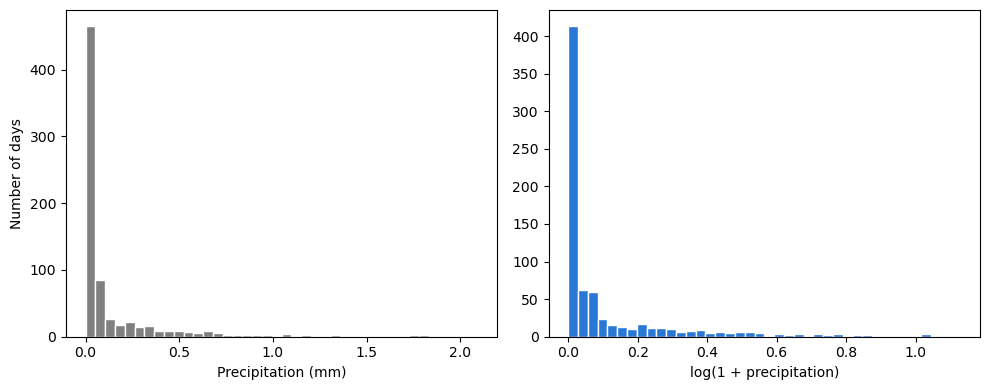

Skew before: 3.5   after: 2.62


In [46]:
# Precipitation is the skewed one: look at it before and after a log transform
# log1p(x) = log(1 + x), so days with 0 mm stay at 0
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df["precip"], bins=40, color="gray", edgecolor="white")
axes[0].set_xlabel("Precipitation (mm)")
axes[0].set_ylabel("Number of days")
axes[1].hist(np.log1p(df["precip"]), bins=40, color="#2a78d6", edgecolor="white")
axes[1].set_xlabel("log(1 + precipitation)")
plt.tight_layout()
plt.show()

print("Skew before:", round(df["precip"].skew(), 2), "  after:", round(np.log1p(df["precip"]).skew(), 2))

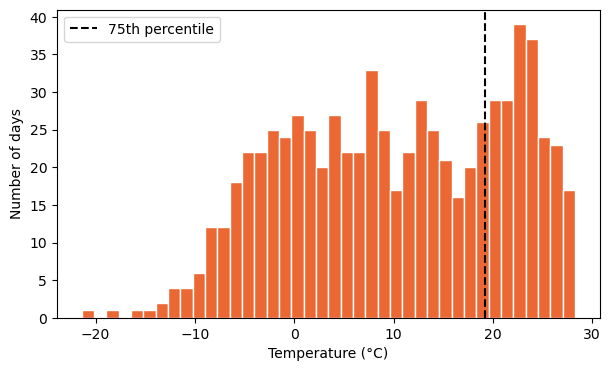

Fraction of hot days, train: 0.253  test: 0.302


In [47]:
# exercise 2

# Regression target: what does the temperature look like?
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["temp"], bins=40, color="#eb6834", edgecolor="white")
ax.axvline(cut, color="black", ls="--", label="75th percentile")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Number of days")
ax.legend()
plt.show()

# Classification target: the hot days
print("Fraction of hot days, train:", round(train["hot"].mean(), 3), " test:", round(test["hot"].mean(), 3))

In [48]:
from sklearn.metrics import precision_score, recall_score

cols = TODAY + ROLL + NEAR
scaler = StandardScaler().fit(train[cols])
Z_train = scaler.transform(train[cols])
Z_test = scaler.transform(test[cols])

for weight in [None, "balanced"]:
    clf = LogisticRegression(max_iter=1000, class_weight=weight).fit(Z_train, train["hot"])
    pred = clf.predict(Z_test)
    print(f"class_weight={str(weight):9s} precision {precision_score(test['hot'], pred):.3f}   recall {recall_score(test['hot'], pred):.3f}")

class_weight=None      precision 0.896   recall 0.936
class_weight=balanced  precision 0.840   recall 0.955


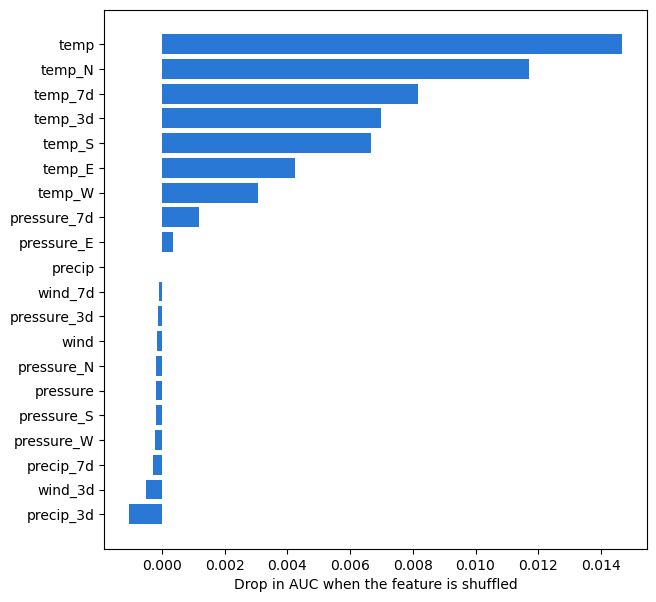

temp_S     0.007
temp_3d    0.007
temp_7d    0.008
temp_N     0.012
temp       0.015
dtype: float64

In [49]:
# exercise 3

from sklearn.inspection import permutation_importance

clf = LogisticRegression(max_iter=1000).fit(Z_train, train["hot"])

result = permutation_importance(clf, Z_test, test["hot"], scoring="roc_auc", n_repeats=10, random_state=0)
importance = pd.Series(result.importances_mean, index=cols).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(importance.index, importance.values, color="#2a78d6")
ax.set_xlabel("Drop in AUC when the feature is shuffled")
plt.show()

importance.tail(5).round(3)